# Bitcoin Volatility: GARCH(1,1) Replication

Python replication of the volatility modelling from my BComHons research project
*"Cryptocurrency Volatility and Financial Stability in South Africa"* (University of Johannesburg, 2025),
originally estimated in EViews. Sample: Feb 2015 – Jan 2025, matching the Financial Stability Index window.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from arch import arch_model

In [2]:
START, END = "2015-02-01", "2025-02-01"

prices = yf.Ticker("BTC-USD").history(start=START, end=END)["Close"]
prices.index = prices.index.tz_localize(None)
print(prices.shape)
prices.head()

(3653,)


Date
2015-02-01    226.972000
2015-02-02    238.229004
2015-02-03    227.268005
2015-02-04    226.852997
2015-02-05    217.110992
Name: Close, dtype: float64

In [3]:
returns = 100 * np.log(prices / prices.shift(1)).dropna()
returns.name = "BTC log return (%)"
returns.describe()

count    3652.000000
mean        0.167357
std         3.591060
min       -46.473018
25%        -1.217127
50%         0.138694
75%         1.646770
max        22.511895
Name: BTC log return (%), dtype: float64

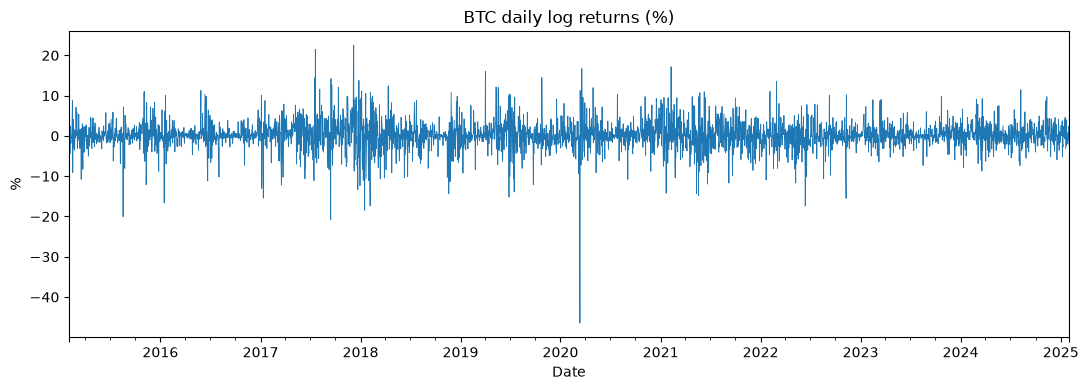

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
returns.plot(ax=ax, lw=0.6)
ax.set_title("BTC daily log returns (%)")
ax.set_ylabel("%")
plt.tight_layout()
plt.savefig("../figures/btc_returns.png", dpi=150)
plt.show()

In [5]:
model = arch_model(returns, mean="Constant", vol="GARCH", p=1, q=1, dist="normal")
res = model.fit(disp="off")
print(res.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:     BTC log return (%)   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -9546.81
Distribution:                  Normal   AIC:                           19101.6
Method:            Maximum Likelihood   BIC:                           19126.4
                                        No. Observations:                 3652
Date:                Sun, Oct 18 2026   Df Residuals:                     3651
Time:                        21:00:30   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.1938  5.257e-02      3.686  2.278e-04 [9.073e-0

In [6]:
alpha = res.params["alpha[1]"]
beta = res.params["beta[1]"]
omega = res.params["omega"]
persistence = alpha + beta
half_life = np.log(0.5) / np.log(persistence)
lr_vol_ann = np.sqrt(omega / (1 - persistence)) * np.sqrt(365)

print(f"alpha (shock reaction):      {alpha:.4f}")
print(f"beta  (memory):              {beta:.4f}")
print(f"alpha + beta (persistence):  {persistence:.4f}")
print(f"Shock half-life (days):      {half_life:.1f}")
print(f"Long-run volatility (ann.):  {lr_vol_ann:.1f}%")

alpha (shock reaction):      0.1248
beta  (memory):              0.8401
alpha + beta (persistence):  0.9649
Shock half-life (days):      19.4
Long-run volatility (ann.):  78.8%


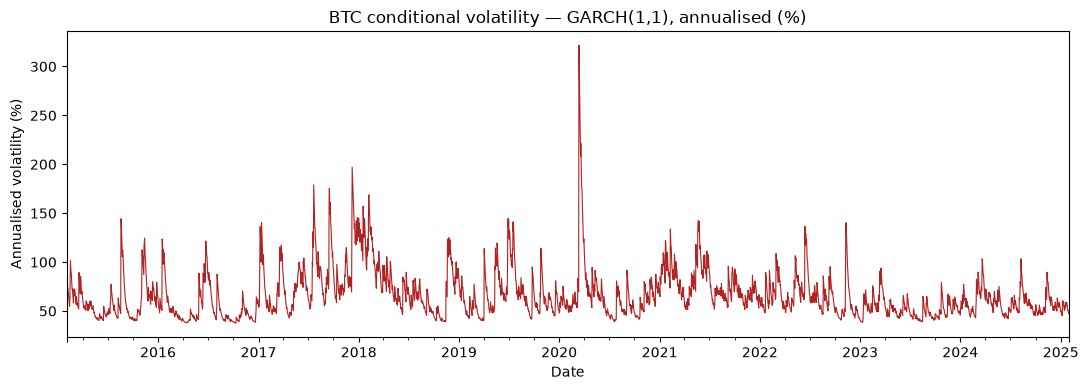

In [7]:
ann_vol = res.conditional_volatility * np.sqrt(365)

fig, ax = plt.subplots(figsize=(11, 4))
ann_vol.plot(ax=ax, lw=0.8, color="firebrick")
ax.set_title("BTC conditional volatility — GARCH(1,1), annualised (%)")
ax.set_ylabel("Annualised volatility (%)")
plt.tight_layout()
plt.savefig("../figures/btc_garch_volatility.png", dpi=150)
plt.show()

## Findings

- **Persistence:** α + β = 0.965 — Volatility shocks die out slowly, meaning a turbulent day predicts turbulent days ahead. Because it's below 1, volatility eventually returns to its long-run level.
- **Half-life:** ~19 days — After a massive shock is felt, it takes about 19 days for the extra volatility to fall by half. Therefore, risk remains high for weeks, not days.
- **Long-run volatility:** ~79% annualised vs ~15–18% for the JSE All Share—Bitcoin's typical volatility (risk) is about 4-5 times that of the JSE All Share, meaning a one-standard deviation move over a year is around 79%.
- **Volatility episodes:** The largest spike experienced was in March 2020 (COVID Crash, above 300% annualised), with further clusters in 2017-18 (crypto bubble and crash) and 2021-22 (bull run alongside the Terra/Luna and FTX collapse): the baseline is noticeably smoother/calmer from 2023.
- **Limitation:** the Normal distribution understates tail risk (the −46% day on 12 March 2020 is roughly 13σ); the next step is Student-t errors.
- **Link to Honours:** despite this high, persistent volatility, my ARDL analysis found no significant spillover to SA financial stability (p = 0.220).